# Laya run 4: does the boundary pull the verdict down? (Kaggle, GPU T4 ×2)

Fourth run, on the **`laya_v2`** dataset (new version: equal passage split + the `v1` control folder). Same labels,
lectures and split as runs 1–3.

**What run 3 showed** (`notebooks/kaggle/finished/wahy-finetuning-laya-v2.ipynb`, `docs/reports/laya-run3-report.md`):
* the short-verse fix works where it was aimed: verses inside a passage, real ones rejected 3/64 → **0/64**;
* but every v2 model is **worse on the verdict** than run 2's `curve_100` (same 2 epochs, old envelope): AUC on your cards
  0.945 → 0.857–0.890, *not-a-quote* caught 85 % → 48–70 %;
* and the yes/no boundary collapsed to "never cut off" (balanced 0.5), except `both_synth` (0.60 / 0.59, still under the
  no-model rule's 0.69 / 0.75).

**The hypothesis:** the boundary questions compete with the verdict inside the one shared model. Run 2 already hinted at
it (more boundary items → lower verdict AUC: 0.945 → 0.93 → 0.918); run 3 doubled the boundary items (two questions per
real quote, "yes" × 3) and the model with the most of them (`both_synth`) has the lowest verdict.

| run | data | trains on | answers |
|---|---|---|---|
| `both_verdict` | v2, passages + neighbours | **verdict only** | without the boundary, does the verdict come back — and keep the short-verse gains? |
| `v1_verdict` | old envelope (laya_v1) | **verdict only** | the control: is it the boundary competing, or the v2 input itself? |
| `boundary_only` | v2 + counterfactual rows | **start / end cut off only** | can Laya learn the boundary when it is its only job? |
| `both` | v2, passages + neighbours | all three (= run 3's `both`, equal split) | how much do numbers move between two identical runs (noise)? |

Also new: the boundary is scored a second time with **thresholds tuned on val** (a model can rank cut-off quotes well and
still never reach 0.5: run 3's AUCs were 0.6–0.75 with balanced 0.5).

**If `both_verdict` wins**, the app is ready: a checkpoint trained on the verdict only carries `wahy_questions: ["verdict"]`,
the app asks it only that (3× fewer readings per finding) and takes the boundary from the word-overlap rule — the best
boundary so far. A boundary-only model is for learning here; the app does not run two Laya models.

### Kaggle settings (right-hand panel)
* **Accelerator:** `GPU T4 x2` · **Internet:** `On` · **Secrets:** `HF_TOKEN`
* **Input:** the `laya_v2` dataset, **new version** made from the rebuilt `data/laya_datagen/laya_v2.zip` (section 3 checks it)
* **Run:** *Save Version → Save & Run All (Commit)*. Expect **~2 h** (4 trainings, 2 of them half-size).
* **Download afterwards:** the `results/` folder → `data/laya_datagen/results/run4/` → `notebooks/results/laya_v2_compare.ipynb`.

## 1. Environment & dual T4 GPU check

In [1]:
!nvidia-smi
import os, subprocess, torch

n_gpu = torch.cuda.device_count()
print(f"CUDA Available: {torch.cuda.is_available()} | Visible GPUs: {n_gpu}")
for i in range(n_gpu):
    p = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {p.name} ({p.total_memory / 1e9:.1f} GB)")

assert n_gpu >= 2, (
    f"Expected 2 GPUs, but detected {n_gpu}! Notebook options -> Accelerator -> GPU T4 x2."
)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

Tue Oct 27 16:27:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   56C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Install dependencies

In [2]:
# pinned to the 0.4 line the Wahy data was validated with (laya.train / laya.calibrate are identical 0.4.12 -> 0.4.15)
!pip install -q -U "laya>=0.4.12,<0.5" "transformers>=4.48.0" safetensors huggingface_hub pandas matplotlib tabulate
import laya, transformers
print("Laya version        :", laya.__version__)
print("Transformers version:", transformers.__version__)
print("PyTorch version     :", torch.__version__)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
ydata-profiling 4.18.4 requires pandas!=1.4.0,<3.0,>1.5, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2

## 3. Dataset, scripts, base checkpoint, Hub login
Stops early if the dataset is the run-3 version (no `v1` folder, no `--questions` in `train_ddp.py`).

In [3]:
import glob, json, sys
from pathlib import Path
from huggingface_hub import snapshot_download, login
from laya.agent import _fix_tokenizer_config

DATA = next(Path(p).parent for p in sorted(glob.glob("/kaggle/input/**/manifest.json", recursive=True))
            if json.loads(Path(p).read_text()).get("name") == "laya_v2")
manifest = json.loads((DATA / "manifest.json").read_text())
assert manifest["envelope"] == 2 and "v1" in manifest["variants"], (
    "This is the run-3 version of laya_v2: upload the rebuilt laya_v2.zip as a NEW VERSION of the dataset, then re-run.")
assert "--questions" in (DATA / "train_ddp.py").read_text() and "def tune_thresholds" in (DATA / "eval_laya.py").read_text(), (
    "Old scripts in the dataset: upload the rebuilt laya_v2.zip as a NEW VERSION of the dataset, then re-run.")
sys.path.insert(0, str(DATA))
import eval_laya

print("dataset:", DATA, "| created", manifest["created"], "| base model", manifest["base_model"],
      "| max_len", manifest["max_len"], "| variants", list(manifest["variants"]))
MODEL_ID = manifest["base_model"]          # convaiinnovations/laya-multilingual
model_dir = snapshot_download(MODEL_ID)
_fix_tokenizer_config(model_dir)
print("base checkpoint:", model_dir)

try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
    login(token=HF_TOKEN)
    print("Hub: logged in")
except Exception as e:
    HF_TOKEN = None
    print("Hub: no HF_TOKEN secret, the 'before' line (private model) and the push will be skipped:", e)

dataset: /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2 | created 2026-10-27 | base model convaiinnovations/laya-multilingual | max_len 2048 | variants ['base', 'passages', 'neighbours', 'both', 'both_synth', 'v1']


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

base checkpoint: /root/.cache/huggingface/hub/models--convaiinnovations--laya-multilingual/snapshots/1720e3e3357cfe1e281542e223f8273b0890ca34
Hub: logged in


## 4. Settings
Run 3's recipe for everything not in `RUNS`: 2 epochs, effective batch 64 (4 × 8 accumulation), RLCD, the same learning
rates, max_len 2048, a "yes, cut off" answer × 3 in the loss.

In [4]:
RUNS = {   # name -> (data folder, questions trained, what it answers)
    "both_verdict":  ("both", ["verdict"], "v2 + D + A, verdict only"),
    "v1_verdict":    ("v1", ["verdict"], "old envelope, verdict only (control)"),
    "boundary_only": ("both_synth", ["start_missing", "end_missing"], "v2 + D + A + counterfactual, boundary only"),
    "both":          ("both", None, "= run 3's both, all questions (noise check)"),
}
NOUL_TRUE_WEIGHT = 3.0
TRAIN_ARGS = (f"--epochs 2 --micro-batch 4 --grad-accum 8 --lr-encoder 2.5e-5 --lr-head 1e-4 --loss rlcd "
              f"--max-len {manifest['max_len']} --head-max-len {manifest['head_max_len']} --noul-true-weight {NOUL_TRUE_WEIGHT}")
APP_FALSE_SHARE = 0.10
BEFORE_MODEL = "ZenoAbderrahim/laya-wahy-soft_asis"     # the app's current model: the "before" line
PUSH_TO_HUB = True
HUB_PREFIX = "ZenoAbderrahim/laya-wahy-r4"              # repo = f"{HUB_PREFIX}-{run}" (run 3's repos stay untouched)

WORK = Path("/kaggle/working")
for d in ("results", "logs"):
    (WORK / d).mkdir(parents=True, exist_ok=True)

def run(cmd, log):
    # Run a shell command, stream its output here and into a log file; returns the exit code.
    print("$", cmd, flush=True)
    with open(log, "w") as f:
        p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        for line in p.stdout:
            f.write(line)
            if "Warning" not in line and "warn(" not in line:
                print(line, end="", flush=True)
        return p.wait()

import pandas as pd
rows = []
for name, (data, qs, about) in RUNS.items():
    tr = manifest["variants"][data]["train"]
    items = (tr["rows"] if not qs or "verdict" in qs else 0) + sum(tr.get(f"{q} items", 0) for q in ("start_missing", "end_missing") if not qs or q in qs)
    rows.append({"run": name, "data": data, "questions": ", ".join(qs) if qs else "all", "about": about,
                 "train rows": tr["rows"], "train items": items, "not a quote (rows)": round(tr.get("verdict FALSE", 0) / tr["rows"], 3)})
pd.DataFrame(rows).set_index("run")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


,data,questions,about,train rows,train items,not a quote (rows)
run,,,,,,
both_verdict,both,verdict,"v2 + D + A, verdict only",2728,2728,0.508
v1_verdict,v1,verdict,"old envelope, verdict only (control)",2863,2863,0.485
boundary_only,both_synth,"start_missing, end_missing","v2 + D + A + counterfactual, boundary only",3428,3989,0.404
both,both,all,"= run 3's both, all questions (noise check)",2728,5325,0.508


## 5. The "before" line: your current app model on the v1 test file
Same as run 3, plus its boundary thresholds tuned on the v1 val file.

In [5]:
flags = f"--verse-flags {DATA}/test_verse_flags.json"
if HF_TOKEN:
    rc = run(f"python {DATA}/eval_laya.py predict --model {BEFORE_MODEL} --name 'before: soft_asis (app)' "
             f"--test {DATA}/v1_test.jsonl --out {WORK}/results/before_soft_asis.json --app-false-share {APP_FALSE_SHARE} "
             f"--batch-size 32 --baselines {DATA}/v1_baselines.json --tune-val {DATA}/v1/val.jsonl {flags}",
             WORK / "logs" / "eval_before.log")
    print("before:", "ok" if rc == 0 else f"failed (exit {rc}), see logs/eval_before.log")

$ python /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2/eval_laya.py predict --model ZenoAbderrahim/laya-wahy-soft_asis --name 'before: soft_asis (app)' --test /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2/v1_test.jsonl --out /kaggle/working/results/before_soft_asis.json --app-false-share 0.1 --batch-size 32 --baselines /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2/v1_baselines.json --tune-val /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2/v1/val.jsonl --verse-flags /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2/test_verse_flags.json

Fetching 5 files: 100%|██████████| 5/5 [00:10<00:00,  2.08s/it]
  640/1523 rows, 46s
  1280/1523 rows, 98s

Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 1010.77it/s]
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| before: soft_asis (app) | 198 | 91.4 % [87–95

## 6. Train + evaluate
`--questions` keeps only those items in train and val; the checkpoint's config records them (`wahy_questions`) so the
evaluation and the app ask it nothing else. Models with a boundary get `--tune-val` (thresholds from their val file).

In [6]:
import time
status = {}
for name, (data, qs, _) in RUNS.items():
    v = manifest["variants"][data]
    out = WORK / "models" / name
    t0 = time.time()
    try:
        extra = dict(v["cfg_extra"], **({"wahy_questions": qs} if qs else {}))
        cfg_extra = json.dumps(extra).replace('"', '\\"')
        qarg = f"--questions {','.join(qs)}" if qs else ""
        rc = run(f"torchrun --standalone --nproc_per_node=2 {DATA}/train_ddp.py {model_dir} {out} "
                 f"--train {DATA}/{data}/train.jsonl --val {DATA}/{data}/val.jsonl --name laya-wahy-r4-{name} "
                 f"--cfg-extra \"{cfg_extra}\" {qarg} {TRAIN_ARGS}", WORK / "logs" / f"train_{name}.log")
        if rc != 0 or not (out / "model.safetensors").exists():
            status[name] = f"training failed (exit {rc}), see logs/train_{name}.log"
            continue
        tr = v["train"]
        tune = f"--tune-val {DATA}/{data}/val.jsonl" if (not qs or "start_missing" in qs) else ""
        rc = run(f"python {DATA}/eval_laya.py predict --model {out} --name {name} --test {DATA}/{data}/test.jsonl "
                 f"--out {WORK}/results/{name}.json --train-false-share {round(tr.get('verdict FALSE', 0) / tr['rows'], 4)} "
                 f"--app-false-share {APP_FALSE_SHARE} --batch-size 16 {tune} {flags}", WORK / "logs" / f"eval_{name}.log")
        status[name] = f"ok in {(time.time() - t0) / 60:.0f} min" if rc == 0 else f"evaluation failed (exit {rc})"
        train_log = out / "train_log.json"
        if train_log.exists():
            (WORK / "results" / f"train_log_{name}.json").write_text(train_log.read_text())
    except Exception as e:
        status[name] = f"error: {e}"
    print(f"\n##### {name}: {status[name]}\n", flush=True)
json.dump(status, open(WORK / "results" / "status.json", "w"), indent=1)
status

$ torchrun --standalone --nproc_per_node=2 /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2/train_ddp.py /root/.cache/huggingface/hub/models--convaiinnovations--laya-multilingual/snapshots/1720e3e3357cfe1e281542e223f8273b0890ca34 /kaggle/working/models/both_verdict --train /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2/both/train.jsonl --val /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2/both/val.jsonl --name laya-wahy-r4-both_verdict --cfg-extra "{\"wahy_envelope\": 2, \"wahy_envelope_options\": {\"passages\": true, \"neighbours\": true}, \"wahy_questions\": [\"verdict\"]}" --questions verdict --epochs 2 --micro-batch 4 --grad-accum 8 --lr-encoder 2.5e-5 --lr-head 1e-4 --loss rlcd --max-len 2048 --head-max-len 256 --noul-true-weight 3.0
W1027 16:31:26.485000 155 torch/distributed/run.py:851] 
W1027 16:31:26.485000 155 torch/distributed/run.py:851] *****************************************
W1027 16:31:26.485000 155 torch/distributed/run.py:851] Setting

{'both_verdict': 'ok in 18 min',
 'v1_verdict': 'ok in 15 min',
 'boundary_only': 'ok in 24 min',
 'both': 'ok in 37 min'}

## 7. Load the results (+ the no-model boundary rule)

In [7]:
from IPython.display import Markdown, display
v1_rows = eval_laya.read_jsonl(DATA / "v1_test.jsonl")
vflags = json.loads((DATA / "test_verse_flags.json").read_text())
res = {n: json.load(open(WORK / "results" / f"{n}.json")) for n in RUNS if (WORK / "results" / f"{n}.json").exists()}
before = [json.load(open(WORK / "results" / "before_soft_asis.json"))] if (WORK / "results" / "before_soft_asis.json").exists() else []
rule = eval_laya.evaluate(*eval_laya.per_verse(v1_rows, eval_laya.rule_predictions(v1_rows), vflags), "word-overlap rule (no model)")
json.dump(rule, open(WORK / "results" / "rule_boundary.json", "w"), ensure_ascii=False)
teachers = [json.load(open(f)) for f in sorted(glob.glob(str(WORK / "results" / "baseline_*.json")))]
models = before + [res[n] for n in RUNS if n in res]
# run 2's curve_100 (old envelope, all questions, 2 epochs) on the same cards, for the verdict reference line
CURVE_100 = {"you": {"AUC": 0.945, "accuracy": 0.894, "not-a-quote recall": 0.852, "real rejected": 0.099},
             "you + Sonnet": {"AUC": 0.954, "accuracy": 0.899, "not-a-quote recall": 0.947, "real rejected": 0.142}}
print("models:", [m["name"] for m in models], "| teacher baselines:", [t["name"] for t in teachers])

models: ['before: soft_asis (app)', 'both_verdict', 'v1_verdict', 'boundary_only', 'both'] | teacher baselines: ['7 shallow fields (LR)', 'Gemini (cached)', 'JEV (cached)', 'Laya (base) (cached)', 'span length only (LR)']


## 8. Verdict
The question of this run: `both_verdict` and `v1_verdict` against `both` (and run 2's `curve_100`: AUC on your cards
0.945, on you + Sonnet 0.954). Then the slices the passages / neighbours are for.

In [8]:
verdict_models = [m for m in models if any((g or {}).get("verdict") for g in m["groups"].values())]
report = []
for g in ["you", "you + Sonnet", "Sonnet · other lectures", "written text"]:
    t = f"### verdict · {g}\n" + eval_laya.compare(verdict_models + teachers, g)
    report.append(t); display(Markdown(t))
for g in ["you", "you + Sonnet"]:
    for part in ("by context", "by span length"):
        t = f"### verdict {part} · {g}\n" + eval_laya.compare_slices(verdict_models, g, part)
        report.append(t); display(Markdown(t))
(WORK / "results" / "comparison.md").write_text("\n\n".join(report))

### verdict · you
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| before: soft_asis (app) | 198 | 91.4 % [87–95] | 77.8 % [59–89] | 65.6 % [48–80] | 6.4 % [4–11] | 0.944 | 0.084 | 44.8 % [37–53] |
| both_verdict | 198 | 83.3 % [78–88] | 55.6 % [37–72] | 41.7 % [27–58] | 12.3 % [8–18] | 0.836 | 0.084 | — |
| v1_verdict | 198 | 91.4 % [87–95] | 63.0 % [44–78] | 70.8 % [51–85] | 4.1 % [2–8] | 0.933 | 0.134 | — |
| both | 198 | 85.9 % [80–90] | 59.3 % [41–75] | 48.5 % [32–65] | 9.9 % [6–15] | 0.904 | 0.086 | 44.8 % [37–53] |
| 7 shallow fields (LR) | 198 | 83.8 % [78–88] | 66.7 % [48–81] | 43.9 % [30–59] | 13.5 % [9–19] | 0.857 | 0.040 | — |
| Gemini (cached) | 147 | 89.8 % [84–94] | 41.7 % [24–61] | 100.0 % [72–100] | 0.0 % [0–3] | 0.708 | 0.102 | 50.0 % [40–60] |
| JEV (cached) | 147 | 86.4 % [80–91] | 20.8 % [9–40] | 100.0 % [57–100] | 0.0 % [0–3] | 0.604 | 0.136 | 52.9 % [43–62] |
| Laya (base) (cached) | 111 | 54.0 % [45–63] | 88.9 % [56–98] | 14.0 % [7–25] | 48.0 % [39–58] | 0.704 | 0.460 | 30.4 % [22–40] |
| span length only (LR) | 198 | 79.3 % [73–84] | 29.6 % [16–48] | 26.7 % [14–44] | 12.9 % [9–19] | 0.723 | 0.109 | — |

### verdict · you + Sonnet
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| before: soft_asis (app) | 1243 | 90.9 % [89–92] | 92.4 % [90–94] | 88.6 % [86–91] | 10.4 % [8–13] | 0.960 | 0.082 | 70.8 % [67–74] |
| both_verdict | 1243 | 88.9 % [87–91] | 90.4 % [88–92] | 86.5 % [84–89] | 12.4 % [10–15] | 0.952 | 0.081 | — |
| v1_verdict | 1243 | 88.4 % [87–90] | 87.9 % [85–90] | 87.4 % [84–90] | 11.2 % [9–14] | 0.952 | 0.083 | — |
| both | 1243 | 88.9 % [87–91] | 89.3 % [87–92] | 87.2 % [84–90] | 11.5 % [9–14] | 0.950 | 0.081 | 70.8 % [67–74] |
| 7 shallow fields (LR) | 1243 | 85.5 % [83–87] | 89.3 % [87–92] | 81.5 % [78–84] | 17.8 % [15–21] | 0.932 | 0.035 | — |
| Gemini (cached) | 180 | 90.0 % [85–94] | 38.5 % [22–57] | 90.9 % [62–98] | 0.7 % [0–4] | 0.689 | 0.100 | 51.9 % [43–60] |
| JEV (cached) | 180 | 87.2 % [82–91] | 19.2 % [9–38] | 83.3 % [44–97] | 0.7 % [0–4] | 0.593 | 0.128 | 54.9 % [46–63] |
| Laya (base) (cached) | 111 | 54.0 % [45–63] | 88.9 % [56–98] | 14.0 % [7–25] | 48.0 % [39–58] | 0.704 | 0.460 | 30.4 % [22–40] |
| span length only (LR) | 1243 | 81.7 % [79–84] | 78.7 % [75–82] | 81.5 % [78–84] | 15.7 % [13–19] | 0.890 | 0.042 | — |

### verdict · Sonnet · other lectures
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| before: soft_asis (app) | 596 | 90.9 % [88–93] | 91.4 % [87–94] | 88.7 % [84–92] | 9.4 % [7–13] | 0.957 | 0.074 | 82.4 % [78–86] |
| both_verdict | 596 | 90.6 % [88–93] | 91.4 % [87–94] | 88.1 % [84–91] | 10.0 % [7–14] | 0.964 | 0.091 | — |
| v1_verdict | 596 | 87.4 % [85–90] | 88.0 % [84–91] | 84.5 % [80–88] | 13.1 % [10–17] | 0.947 | 0.081 | — |
| both | 596 | 89.3 % [87–92] | 88.8 % [84–92] | 87.5 % [83–91] | 10.3 % [7–14] | 0.956 | 0.091 | 82.4 % [78–86] |
| 7 shallow fields (LR) | 596 | 86.6 % [84–89] | 91.8 % [88–94] | 80.9 % [76–85] | 17.6 % [14–22] | 0.941 | 0.057 | — |
| span length only (LR) | 596 | 81.9 % [79–85] | 80.9 % [76–85] | 79.1 % [74–84] | 17.3 % [14–22] | 0.897 | 0.051 | — |

### verdict · written text
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| before: soft_asis (app) | 280 | 90.4 % [86–93] | 83.3 % [44–97] | 16.1 % [7–33] | 9.5 % [7–14] | 0.843 | 0.073 | 62.4 % [56–68] |
| both_verdict | 280 | 88.6 % [84–92] | 83.3 % [44–97] | 13.9 % [6–29] | 11.3 % [8–16] | 0.882 | 0.069 | — |
| v1_verdict | 280 | 90.4 % [86–93] | 83.3 % [44–97] | 16.1 % [7–33] | 9.5 % [7–14] | 0.866 | 0.070 | — |
| both | 280 | 91.1 % [87–94] | 66.7 % [30–90] | 14.8 % [6–32] | 8.4 % [6–12] | 0.830 | 0.113 | 62.4 % [56–68] |
| 7 shallow fields (LR) | 280 | 92.9 % [89–95] | 83.3 % [44–97] | 20.8 % [9–40] | 6.9 % [4–11] | 0.904 | 0.051 | — |
| span length only (LR) | 280 | 82.9 % [78–87] | 83.3 % [44–97] | 9.6 % [4–21] | 17.2 % [13–22] | 0.919 | 0.169 | — |

### verdict by context · you
| model | inside a passage of consecutive verses (acc · real rejected) | next to a verse of the same surah (<= 3 ayat away) (acc · real rejected) | short (1-3 words) and isolated (acc · real rejected) | short (1-3 words) with a same-surah verse around (acc · real rejected) | has any neighbour finding (<= 40 words) (acc · real rejected) | no neighbour finding (acc · real rejected) |
|---|---|---|---|---|---|---|
| before: soft_asis (app) | 100.0 % [76–100] · 0/12 | 81.8 % [52–95] · 2/11 | 69.2 % [42–87] · 3/7 | 100.0 % [51–100] · 0/4 | 93.3 % [88–96] · 5/120 | 87.3 % [77–93] · 6/51 |
| both_verdict | 100.0 % [76–100] · 0/12 | 72.7 % [43–90] · 3/11 | 61.5 % [36–82] · 5/7 | 75.0 % [30–95] · 1/4 | 87.4 % [81–92] · 13/120 | 74.6 % [63–84] · 8/51 |
| v1_verdict | 100.0 % [76–100] · 0/12 | 100.0 % [74–100] · 0/11 | 76.9 % [50–92] · 3/7 | 100.0 % [51–100] · 0/4 | 93.3 % [88–96] · 4/120 | 87.3 % [77–93] · 3/51 |
| both | 100.0 % [76–100] · 0/12 | 63.6 % [35–85] · 4/11 | 69.2 % [42–87] · 3/7 | 75.0 % [30–95] · 1/4 | 88.9 % [82–93] · 9/120 | 79.4 % [68–88] · 8/51 |

### verdict by span length · you
| model | 1-3 words (acc · real rejected) | 4-8 words (acc · real rejected) | 9+ words (acc · real rejected) |
|---|---|---|---|
| before: soft_asis (app) | 76.5 % [53–90] · 3/11 | 85.3 % [76–92] · 7/60 | 98.1 % [93–99] · 1/100 |
| both_verdict | 64.7 % [41–83] · 6/11 | 69.3 % [58–79] · 13/60 | 96.2 % [91–99] · 2/100 |
| v1_verdict | 82.3 % [59–94] · 3/11 | 86.7 % [77–93] · 4/60 | 96.2 % [91–99] · 0/100 |
| both | 70.6 % [47–87] · 4/11 | 74.7 % [64–83] · 11/60 | 96.2 % [91–99] · 2/100 |

### verdict by context · you + Sonnet
| model | inside a passage of consecutive verses (acc · real rejected) | next to a verse of the same surah (<= 3 ayat away) (acc · real rejected) | short (1-3 words) and isolated (acc · real rejected) | short (1-3 words) with a same-surah verse around (acc · real rejected) | has any neighbour finding (<= 40 words) (acc · real rejected) | no neighbour finding (acc · real rejected) |
|---|---|---|---|---|---|---|
| before: soft_asis (app) | 95.4 % [87–98] · 3/65 | 79.5 % [66–89] · 7/33 | 91.9 % [89–94] · 23/39 | 82.6 % [63–93] · 3/14 | 91.0 % [89–93] · 57/510 | 90.3 % [86–93] · 12/152 |
| both_verdict | 100.0 % [94–100] · 0/65 | 84.1 % [71–92] · 6/33 | 91.4 % [88–94] · 29/39 | 87.0 % [68–95] · 3/14 | 90.0 % [88–92] · 70/510 | 84.5 % [79–89] · 12/152 |
| v1_verdict | 95.4 % [87–98] · 3/65 | 79.5 % [66–89] · 5/33 | 89.1 % [86–92] · 30/39 | 73.9 % [54–87] · 4/14 | 88.5 % [86–90] · 66/510 | 88.2 % [84–92] · 8/152 |
| both | 100.0 % [94–100] · 0/65 | 81.8 % [68–90] · 6/33 | 90.1 % [87–93] · 26/39 | 82.6 % [63–93] · 2/14 | 89.6 % [88–91] · 58/510 | 85.7 % [81–90] · 18/152 |

### verdict by span length · you + Sonnet
| model | 1-3 words (acc · real rejected) | 4-8 words (acc · real rejected) | 9+ words (acc · real rejected) |
|---|---|---|---|
| before: soft_asis (app) | 91.4 % [88–94] · 26/53 | 84.9 % [81–88] · 37/256 | 97.6 % [96–99] · 6/353 |
| both_verdict | 91.1 % [88–93] · 32/53 | 80.9 % [77–84] · 42/256 | 96.0 % [94–98] · 8/353 |
| v1_verdict | 88.2 % [85–91] · 34/53 | 82.9 % [79–86] · 36/256 | 95.2 % [93–97] · 4/353 |
| both | 89.7 % [86–92] · 28/53 | 82.4 % [79–86] · 42/256 | 95.7 % [93–97] · 6/353 |

7681

## 9. Boundary — at 0.5, then with thresholds tuned on val
**Balanced accuracy** is the column to read. The second table cuts each model's P(cut off) where its val file says,
which is what the app would do with that model.

In [9]:
boundary_models = [m for m in models if any((g or {}).get("boundary") for g in m["groups"].values())]
tuned = [dict(m["tuned"], name=m["tuned"]["name"]) for m in boundary_models if m.get("tuned")]
btext = []
for title, ms in (("at 0.5", boundary_models), ("thresholds tuned on val", tuned)):
    for g in ["you", "written text", "you + Sonnet"]:
        t = f"### boundary {title} · {g}\n" + eval_laya.compare_boundary([rule] + (teachers if title == "at 0.5" else []) + ms, g)
        btext.append(t); display(Markdown(t))
(WORK / "results" / "boundary.md").write_text("\n\n".join(btext))
print("thresholds:", {m["name"]: m.get("thresholds") for m in boundary_models})

logs = {n: json.load(open(WORK / "results" / f"train_log_{n}.json")) for n in RUNS if (WORK / "results" / f"train_log_{n}.json").exists()}
display(pd.DataFrame([{"run": n, **{f"ep{e['epoch']} {k}": e["val"][k].get("balanced_accuracy", round(e["val"][k]["accuracy"], 4))
                                    for e in logs[n]["epochs"] for k in e["val"] if k != "all"}}
                      for n in logs]).set_index("run"))

### boundary at 0.5 · you
| model | cards | accuracy | **balanced accuracy** | cut-off quotes caught | COMPLETE_SPAN | MISSING_START | MISSING_END | MISSING_BOTH | start: balanced / AUC | end: balanced / AUC |
|---|---|---|---|---|---|---|---|---|---|---|
| word-overlap rule (no model) | 143 | 60.8 % [53–68] | **0.506** | 64.6 % [54–74] | 85.9 % [75–92] | 39.1 % [22–59] | 47.2 % [32–63] | 30.0 % [15–52] | 0.686 / 0.686 | 0.748 / 0.748 |
| Gemini (cached) | 102 | 50.0 % [40–60] | **0.396** | 31.8 % [22–44] | 94.9 % [83–99] | 22.2 % [9–45] | 30.8 % [16–50] | 10.5 % [3–31] | 0.593 / 0.593 | 0.627 / 0.627 |
| JEV (cached) | 102 | 52.9 % [43–62] | **0.424** | 33.3 % [23–46] | 100.0 % [91–100] | 11.1 % [3–33] | 26.9 % [14–46] | 31.6 % [15–54] | 0.620 / 0.620 | 0.669 / 0.669 |
| Laya (base) (cached) | 102 | 30.4 % [22–40] | **0.293** | 60.3 % [48–71] | 43.6 % [29–59] | 0.0 % [0–18] | 0.0 % [0–13] | 73.7 % [51–88] | 0.528 / 0.528 | 0.550 / 0.550 |
| before: soft_asis (app) | 143 | 44.8 % [37–53] | **0.250** | 0.0 % [0–5] | 100.0 % [94–100] | 0.0 % [0–14] | 0.0 % [0–10] | 0.0 % [0–16] | 0.500 / 0.647 | 0.500 / 0.615 |
| boundary_only | 143 | 51.0 % [43–59] | **0.338** | 21.5 % [14–32] | 96.9 % [89–99] | 21.7 % [10–42] | 16.7 % [8–32] | 0.0 % [0–16] | 0.561 / 0.719 | 0.575 / 0.763 |
| both | 143 | 44.8 % [37–53] | **0.250** | 0.0 % [0–5] | 100.0 % [94–100] | 0.0 % [0–14] | 0.0 % [0–10] | 0.0 % [0–16] | 0.500 / 0.600 | 0.500 / 0.617 |

### boundary at 0.5 · written text
| model | cards | accuracy | **balanced accuracy** | cut-off quotes caught | COMPLETE_SPAN | MISSING_START | MISSING_END | MISSING_BOTH | start: balanced / AUC | end: balanced / AUC |
|---|---|---|---|---|---|---|---|---|---|---|
| word-overlap rule (no model) | 271 | 76.4 % [71–81] | **0.673** | 77.5 % [68–84] | 84.6 % [78–89] | 60.5 % [46–74] | 69.2 % [54–81] | 55.0 % [34–74] | 0.808 / 0.808 | 0.823 / 0.823 |
| before: soft_asis (app) | 271 | 62.4 % [56–68] | **0.250** | 0.0 % [0–4] | 100.0 % [98–100] | 0.0 % [0–8] | 0.0 % [0–9] | 0.0 % [0–16] | 0.500 / 0.762 | 0.500 / 0.697 |
| boundary_only | 271 | 65.7 % [60–71] | **0.396** | 34.3 % [26–44] | 88.8 % [83–93] | 44.2 % [30–59] | 20.5 % [11–36] | 5.0 % [1–24] | 0.664 / 0.847 | 0.546 / 0.733 |
| both | 271 | 62.4 % [56–68] | **0.250** | 0.0 % [0–4] | 100.0 % [98–100] | 0.0 % [0–8] | 0.0 % [0–9] | 0.0 % [0–16] | 0.500 / 0.686 | 0.500 / 0.683 |

### boundary at 0.5 · you + Sonnet
| model | cards | accuracy | **balanced accuracy** | cut-off quotes caught | COMPLETE_SPAN | MISSING_START | MISSING_END | MISSING_BOTH | start: balanced / AUC | end: balanced / AUC |
|---|---|---|---|---|---|---|---|---|---|---|
| word-overlap rule (no model) | 634 | 68.9 % [65–72] | **0.426** | 47.0 % [40–54] | 85.1 % [81–88] | 31.1 % [22–42] | 30.2 % [22–41] | 24.0 % [12–43] | 0.635 / 0.635 | 0.670 / 0.670 |
| Gemini (cached) | 133 | 51.9 % [43–60] | **0.360** | 28.2 % [19–40] | 88.7 % [78–94] | 19.1 % [8–40] | 25.8 % [14–43] | 10.5 % [3–31] | 0.579 / 0.579 | 0.600 / 0.600 |
| JEV (cached) | 133 | 54.9 % [46–63] | **0.401** | 31.0 % [21–42] | 91.9 % [82–97] | 14.3 % [5–35] | 22.6 % [11–40] | 31.6 % [15–54] | 0.600 / 0.600 | 0.642 / 0.642 |
| Laya (base) (cached) | 102 | 30.4 % [22–40] | **0.293** | 60.3 % [48–71] | 43.6 % [29–59] | 0.0 % [0–18] | 0.0 % [0–13] | 73.7 % [51–88] | 0.528 / 0.528 | 0.550 / 0.550 |
| before: soft_asis (app) | 634 | 70.8 % [67–74] | **0.250** | 0.0 % [0–2] | 100.0 % [99–100] | 0.0 % [0–5] | 0.0 % [0–4] | 0.0 % [0–13] | 0.500 / 0.644 | 0.500 / 0.610 |
| boundary_only | 634 | 69.4 % [66–73] | **0.303** | 18.9 % [14–25] | 93.1 % [90–95] | 17.6 % [11–28] | 10.5 % [6–19] | 0.0 % [0–13] | 0.552 / 0.676 | 0.545 / 0.717 |
| both | 634 | 70.8 % [67–74] | **0.250** | 0.0 % [0–2] | 100.0 % [99–100] | 0.0 % [0–5] | 0.0 % [0–4] | 0.0 % [0–13] | 0.500 / 0.583 | 0.500 / 0.562 |

### boundary thresholds tuned on val · you
| model | cards | accuracy | **balanced accuracy** | cut-off quotes caught | COMPLETE_SPAN | MISSING_START | MISSING_END | MISSING_BOTH | start: balanced / AUC | end: balanced / AUC |
|---|---|---|---|---|---|---|---|---|---|---|
| word-overlap rule (no model) | 143 | 60.8 % [53–68] | **0.506** | 64.6 % [54–74] | 85.9 % [75–92] | 39.1 % [22–59] | 47.2 % [32–63] | 30.0 % [15–52] | 0.686 / 0.686 | 0.748 / 0.748 |
| before: soft_asis (app) (tuned 0.21/0.13) | 143 | 38.5 % [31–47] | **0.336** | 93.7 % [86–97] | 40.6 % [29–53] | 0.0 % [0–14] | 63.9 % [48–78] | 30.0 % [15–52] | 0.559 / 0.647 | 0.620 / 0.615 |
| boundary_only (tuned 0.34/0.17) | 143 | 46.2 % [38–54] | **0.461** | 92.4 % [84–96] | 43.8 % [32–56] | 17.4 % [7–37] | 58.3 % [42–73] | 65.0 % [43–82] | 0.637 / 0.719 | 0.712 / 0.763 |
| both (tuned 0.16/0.16) | 143 | 32.2 % [25–40] | **0.299** | 67.1 % [56–76] | 46.9 % [35–59] | 4.3 % [1–21] | 8.3 % [3–22] | 60.0 % [39–78] | 0.571 / 0.600 | 0.554 / 0.617 |

### boundary thresholds tuned on val · written text
| model | cards | accuracy | **balanced accuracy** | cut-off quotes caught | COMPLETE_SPAN | MISSING_START | MISSING_END | MISSING_BOTH | start: balanced / AUC | end: balanced / AUC |
|---|---|---|---|---|---|---|---|---|---|---|
| word-overlap rule (no model) | 271 | 76.4 % [71–81] | **0.673** | 77.5 % [68–84] | 84.6 % [78–89] | 60.5 % [46–74] | 69.2 % [54–81] | 55.0 % [34–74] | 0.808 / 0.808 | 0.823 / 0.823 |
| before: soft_asis (app) (tuned 0.21/0.13) | 271 | 32.5 % [27–38] | **0.273** | 88.2 % [81–93] | 40.8 % [34–48] | 0.0 % [0–8] | 28.2 % [17–44] | 40.0 % [22–61] | 0.617 / 0.762 | 0.583 / 0.697 |
| boundary_only (tuned 0.34/0.17) | 271 | 48.7 % [43–55] | **0.512** | 84.3 % [76–90] | 46.8 % [39–54] | 44.2 % [30–59] | 59.0 % [43–73] | 55.0 % [34–74] | 0.732 / 0.847 | 0.667 / 0.733 |
| both (tuned 0.16/0.16) | 271 | 43.5 % [38–50] | **0.411** | 71.6 % [62–79] | 52.7 % [45–60] | 16.3 % [8–30] | 15.4 % [7–30] | 80.0 % [58–92] | 0.629 / 0.686 | 0.660 / 0.683 |

### boundary thresholds tuned on val · you + Sonnet
| model | cards | accuracy | **balanced accuracy** | cut-off quotes caught | COMPLETE_SPAN | MISSING_START | MISSING_END | MISSING_BOTH | start: balanced / AUC | end: balanced / AUC |
|---|---|---|---|---|---|---|---|---|---|---|
| word-overlap rule (no model) | 634 | 68.9 % [65–72] | **0.426** | 47.0 % [40–54] | 85.1 % [81–88] | 31.1 % [22–42] | 30.2 % [22–41] | 24.0 % [12–43] | 0.635 / 0.635 | 0.670 / 0.670 |
| before: soft_asis (app) (tuned 0.21/0.13) | 634 | 32.2 % [29–36] | **0.309** | 93.0 % [88–96] | 33.0 % [29–37] | 0.0 % [0–5] | 54.6 % [44–65] | 36.0 % [20–55] | 0.573 / 0.644 | 0.605 / 0.610 |
| boundary_only (tuned 0.34/0.17) | 634 | 35.8 % [32–40] | **0.434** | 92.4 % [88–95] | 34.1 % [30–39] | 16.2 % [10–26] | 51.2 % [41–61] | 72.0 % [52–86] | 0.612 / 0.676 | 0.653 / 0.717 |
| both (tuned 0.16/0.16) | 634 | 31.1 % [28–35] | **0.296** | 69.7 % [63–76] | 37.9 % [34–42] | 5.4 % [2–13] | 7.0 % [3–14] | 68.0 % [48–83] | 0.539 / 0.583 | 0.528 / 0.562 |

thresholds: {'before: soft_asis (app)': {'start': 0.2131, 'end': 0.1251}, 'boundary_only': {'start': 0.3374, 'end': 0.1704}, 'both': {'start': 0.1616, 'end': 0.1576}}


,ep1 verdict,ep2 verdict,ep1 end_missing,ep1 start_missing,ep2 end_missing,ep2 start_missing
run,,,,,,
both_verdict,0.8266,0.8488,NaN,NaN,NaN,NaN
v1_verdict,0.8660,0.8757,NaN,NaN,NaN,NaN
boundary_only,NaN,NaN,0.5623,0.5704,0.6066,0.6112
both,0.8468,0.8569,0.5000,0.5000,0.5000,0.5000


## 10. One picture

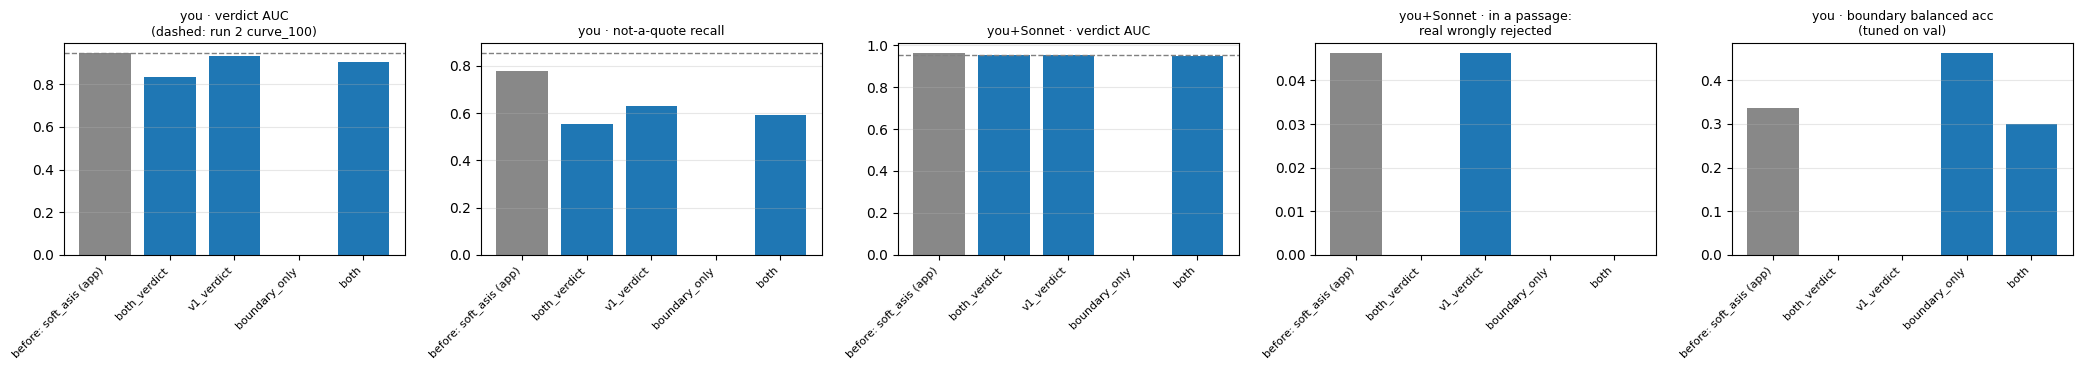

In [10]:
import matplotlib.pyplot as plt

def val(m, group, part, key, src="groups"):
    x = ((m.get(src) or {}).get("groups", m.get(src)) if src != "groups" else m["groups"])
    x = ((x or {}).get(group) or {}).get(part) or {}
    x = x.get(key)
    return x[0] if isinstance(x, list) else x

def slice_rej(m, group, name):
    for sl in ((m["groups"].get(group) or {}).get("verdict") or {}).get("by context", []):
        if sl["slice"] == name:
            return sl["real quotes wrongly rejected"][0]

panels = [("you · verdict AUC\n(dashed: run 2 curve_100)", lambda m: val(m, "you", "verdict", "AUC P(not a quote)"), CURVE_100["you"]["AUC"]),
          ("you · not-a-quote recall", lambda m: val(m, "you", "verdict", "not-a-quote recall"), CURVE_100["you"]["not-a-quote recall"]),
          ("you+Sonnet · verdict AUC", lambda m: val(m, "you + Sonnet", "verdict", "AUC P(not a quote)"), CURVE_100["you + Sonnet"]["AUC"]),
          ("you+Sonnet · in a passage:\nreal wrongly rejected", lambda m: slice_rej(m, "you + Sonnet", "inside a passage of consecutive verses"), None),
          ("you · boundary balanced acc\n(tuned on val)", lambda m: val(m, "you", "boundary", "balanced accuracy", "tuned"), None)]
names = [m["name"] for m in models]
fig, ax = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 3.8))
for a, (title, f, ref) in zip(ax, panels):
    ys = [f(m) for m in models]
    a.bar(range(len(models)), [y if y is not None else 0 for y in ys], color=["#888"] + ["C0"] * (len(models) - 1))
    if ref is not None:
        a.axhline(ref, ls="--", c="grey", lw=1)
    a.set_xticks(range(len(models)), names, rotation=45, ha="right", fontsize=8); a.set_title(title, fontsize=9); a.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(WORK / "results" / "run4.png", dpi=120); plt.show()

## 11. (Optional) Push the models to the Hugging Face Hub — private
`both_verdict` / `v1_verdict` work in the app as they are (verdict from the model, boundary from the rule).
`boundary_only` answers no verdict: keep it for study, do not load it in the app.

In [11]:
if PUSH_TO_HUB and HF_TOKEN:
    from huggingface_hub import HfApi
    api = HfApi(token=HF_TOKEN)
    for n in RUNS:
        out = WORK / "models" / n
        if not (out / "model.safetensors").exists():
            continue
        repo = f"{HUB_PREFIX}-{n}"
        api.create_repo(repo, repo_type="model", private=True, exist_ok=True)
        api.upload_folder(folder_path=str(out), repo_id=repo, repo_type="model",
                          commit_message=f"laya-multilingual fine-tuned on Wahy laya_v2 (run 4: {n}, {RUNS[n][2]})")
        print("pushed", repo)

pushed ZenoAbderrahim/laya-wahy-r4-both_verdict
pushed ZenoAbderrahim/laya-wahy-r4-v1_verdict
pushed ZenoAbderrahim/laya-wahy-r4-boundary_only
pushed ZenoAbderrahim/laya-wahy-r4-both
